intro_to_Language_modeling part2 - MLP

[viedo link](https://youtu.be/TCH_1BHY58I)

[link](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf)

Previous model was for predicting next char when a single char was given and we had only one layer.
Now we will improve the model to handle multiple input char(3 in this case) with multiple hidden layer

Goal: given 3 char we get the next most likely char. This is a classification model - Bcoz, the model is trying to classify the input sequence into one of the 27 possible next characters

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [ ]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   706k      0 --:--:-- --:--:-- --:--:--  707k


In [ ]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

build dataset. i.e build x's and y's
-----


In [ ]:
# build the vocabulary of characters and lookup mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [ ]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:5]:

  print(f'{w=}')
  context = [0] * block_size # create a list with len 3
  for ch in w + '.':
    ix = stoi[ch] # get char's index
    X.append(context) # initially it will be [0,0,0]
    Y.append(ix)
    #print(context, '--->', itos[ix])
    print('given '+''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append. eg [0,0] + [5] = [0,0,5] . where 5 is the index of char 'e'

X = torch.tensor(X) #shape [32, 3]
Y = torch.tensor(Y) #shape [32]

w='emma'
given ... ---> e
given ..e ---> m
given .em ---> m
given emm ---> a
given mma ---> .
w='olivia'
given ... ---> o
given ..o ---> l
given .ol ---> i
given oli ---> v
given liv ---> i
given ivi ---> a
given via ---> .
w='ava'
given ... ---> a
given ..a ---> v
given .av ---> a
given ava ---> .
w='isabella'
given ... ---> i
given ..i ---> s
given .is ---> a
given isa ---> b
given sab ---> e
given abe ---> l
given bel ---> l
given ell ---> a
given lla ---> .
w='sophia'
given ... ---> s
given ..s ---> o
given .so ---> p
given sop ---> h
given oph ---> i
given phi ---> a
given hia ---> .


In [ ]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

Build a lookup table for input embeddings.
-----

using this table we could pick the corresponding embedding for the input char


In [ ]:
# Here we are using 27X2, as there are 27 char and we going to represent each char with 2 random numbers
C = torch.randn((27, 2)) # this will be used as the input embedding lookup.

In [ ]:
# so if we want to lookup for char 'e' whose index is 5 we can get embedding of it as following
C[5]

tensor([0.2880, 0.1204])

Embedding the inputs(i.e X)
-----

In [ ]:
# suppose we want to get the embedding for a single item in X  ,say
X[1] # this would be [0, 0, 5] and which in character form would be [..e]

#embedding of X[1]
C[X[1]] # each 3 char of X(..e) is converted to its corresponding embeddings
#C[X[1]].shape # [3, 2]

tensor([[-0.2286,  0.4698],
        [-0.2286,  0.4698],
        [ 0.2880,  0.1204]])

In [ ]:
# so embedding for the entire input X
emb = C[X]
emb.shape # shape [32, 3, 2].  32 inputs with 3 chars each and each char with two values

torch.Size([32, 3, 2])

Build hidden layer1
-----

In [ ]:
#random weights for 6 inputs(6 bcoz, we provide 3 inputs char of 2 values each)
W1 = torch.randn((6, 100)) # here we use 100 neurons just as an example
#random biases for 100 neurons
b1 = torch.randn(100)

In [ ]:
# next what we want is to do summazation (emb @ W1)+ b1
# First we convert the 'emb' to shape [32,6], bcoz we cannot matrix multiply 'emb'of shape [32, 3, 2] and weights W1 of shape [6, 100]

In [ ]:
# Optional
emb[:,0,:] # all 32 input embeddings with first char out of the 3 chars
emb[:,1,:] # all 32 input embeddings with second char
emb[:,2,:] # all 32 input embeddings with third char

# now we can concat above 3 sequence of shape[32,2] to form a [32,6] shape tensor
torch.cat((emb[:,0,:], emb[:,1,:], emb[:,2,:]), 1).shape # here last arg 1 say to concat along the dim 1

# alternately, we can use torch.unbind instead of maually getting each seperate sequence as above
torch.unbind(emb, 1)
# and then concat
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([32, 6])

In [ ]:
# The efficent way convert [32,3,2] to [32,6] is to use tensor.view.  instead of using the torch.cat and torch.unbind we can use torch.view
# emb.view(32, 6)
# emb.view(-1, 6)# When we give -1,pytorch will infer what shape that -1 will be based on the other shape we supplied

h = torch.tanh(emb.view(-1, 6) @ W1 + b1) #doing summazation and activation-func
h.shape #[32, 100]

torch.Size([32, 100])

Build output layer
-----

In [ ]:
#random weights for 100 inputs(100 bcoz, we 100 inputs from previous hidden layer)
W2 = torch.randn((100, 27)) # here we use 27 neurons as we have 27 possible chars
b2 = torch.randn(27)

In [ ]:
#logits - refer specifically to the raw, unnormalized output values of a model's final laye
logits = h @ W2 + b2
logits.shape #so, for 32 input we get logits of shape [32, 27]

torch.Size([32, 27])

In [ ]:
# output layer activation-fun (softmax activation-fun in this case)
counts = logits.exp() # exponentiated logits to get a fake count
prob = counts / counts.sum(1, keepdim=True) #normalize

#prob[0].sum() # this should be 1

Loss calculation
-----

In [ ]:
# now we check what probalities the model has given for the labels(i.e Y)
prob[torch.arange(32), Y] #torch.arange(32) is just mocking inputs index
#log the probablities
prob[torch.arange(32), Y].log() # Since probabilities are always between 0 and 1, taking the logarithm of a probability (unless it's exactly 1) will result in a negative number.
log_likelihood = prob[torch.arange(32), Y].log().mean()
neg_log_likelihood = -log_likelihood

loss = -prob[torch.arange(32), Y].log().mean() # same as above done in a single step
loss

tensor(20.5992)

Refactoring-01
-----

In [ ]:
print(f'dataset X:{X.shape} Y:{Y.shape}') # dataset

dataset X:torch.Size([32, 3]) Y:torch.Size([32])


In [ ]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

total parameters 3481


In [ ]:
# setting grad as required for all parameters
for p in parameters:
  p.requires_grad = True

In [ ]:
for i in range(1000):
  # forward pass
  emb = C[X] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)
  counts = logits.exp()
  probs = counts / counts.sum(1, keepdims=True)
  loss = -probs[torch.arange(32), Y].log().mean()
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  for p in parameters:
    p.data += -0.1 * p.grad

print("loss",loss.item())

loss 0.2561504542827606


Refactoring-02
-----
using pytorch CROSS_ENTROPY to calculate loss

In [ ]:
print(f'dataset X:{X.shape} Y:{Y.shape}') # dataset

dataset X:torch.Size([32, 3]) Y:torch.Size([32])


In [ ]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

total parameters 3481


In [ ]:
# setting grad as required for all parameters
for p in parameters:
  p.requires_grad = True

In [ ]:
for i in range(1000):
  # forward pass
  emb = C[X] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)
  # counts = logits.exp()
  # probs = counts / counts.sum(1, keepdims=True)
  # loss = -probs[torch.arange(32), Y].log().mean()
  loss = F.cross_entropy(logits, Y) # https://youtu.be/TCH_1BHY58I?t=2005
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  for p in parameters:
    p.data += -0.1 * p.grad # 0.1 is the learning rate

print("loss",loss.item())

loss 0.2561509907245636


Refactoring-03
-----
Here we do training with the full dataset

In [ ]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  context = [0] * block_size # create a list with len 3
  for ch in w + '.':
    ix = stoi[ch] # get char's index
    X.append(context) # initially it will be [0,0,0]
    Y.append(ix)
    #print('given '+''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append. eg [0,0] + [5] = [0,0,5] . where 5 is the index of char 'e'

X = torch.tensor(X) #shape [228146, 3]
Y = torch.tensor(Y) #shape [[228146]]
print(f'dataset X:{X.shape} Y:{Y.shape}')

dataset X:torch.Size([228146, 3]) Y:torch.Size([228146])


In [ ]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

total parameters 3481


In [ ]:
# setting grad as required for all parameters
for p in parameters:
  p.requires_grad = True

In [ ]:
for i in range(100):
  # forward pass
  emb = C[X] # (228146, 3, 10)
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
  logits = h @ W2 + b2 # (228146, 27)
  loss = F.cross_entropy(logits, Y) # https://youtu.be/TCH_1BHY58I?t=2005
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  for p in parameters:
    p.data += -0.1 * p.grad # 0.1 is the learning rate

print("loss",loss.item())

loss 3.5892493724823


Refactoring-04
-----
Here we do training in mini batches.

By training on mini-batches, you get a more frequent update to the model's parameters, which can lead to faster convergence and can also help the model escape local minima in the loss landscape.


The key benefits of using mini-batches, even with a small batch size like 32, are:

1. Computational Efficiency:
Processing data in small batches is much more computationally efficient than processing the entire dataset at once, especially when the dataset is very large (like your X tensor with over 200,000 data points). It requires less memory and can often be processed in parallel by hardware like GPUs. Training on the full dataset in one go (called batch gradient descent) can be infeasible due to memory constraints.

2. Faster Updates: With mini-batches, the model's parameters are updated after every batch. If you have a large dataset, training on the full dataset would mean waiting until you've processed all data points before making a single update to the parameters. Mini-batch training allows for much more frequent updates, which helps the model converge faster to a good solution.

3. Noise and Regularization: The randomness introduced by selecting different mini-batches in each iteration adds a form of noise to the training process. This noise can actually be beneficial as it helps the model avoid getting stuck in sharp local minima in the loss landscape and can lead to better generalization on unseen data. It acts as a regularizer.

4. Approximation of the Full Gradient: While the gradient calculated on a single mini-batch is a noisy estimate of the true gradient (the gradient calculated on the entire dataset), it's often a good enough approximation to guide the model towards the minimum of the loss function. As the batch size increases, the mini-batch gradient becomes a better approximation of the true gradient, but you lose some of the benefits of faster updates and regularization.

https://youtu.be/TCH_1BHY58I?t=2547

In [ ]:
# # build the dataset
# block_size = 3 # context length: how many characters do we take to predict the next one?
# X, Y = [], []
# for w in words:
#   context = [0] * block_size # create a list with len 3
#   for ch in w + '.':
#     ix = stoi[ch] # get char's index
#     X.append(context) # initially it will be [0,0,0]
#     Y.append(ix)
#     #print('given '+''.join(itos[i] for i in context), '--->', itos[ix])
#     context = context[1:] + [ix] # crop and append. eg [0,0] + [5] = [0,0,5] . where 5 is the index of char 'e'

# X = torch.tensor(X) #shape [228146, 3]
# Y = torch.tensor(Y) #shape [[228146]]
# print(f'dataset X:{X.shape} Y:{Y.shape}') # dataset

In [ ]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

total parameters 3481


In [ ]:
# setting grad as required to all parameters
for p in parameters:
  p.requires_grad = True

In [ ]:
for i in range(100):
  # mini-batch construct - creating 32 random no between 0 and no of inputs(X.shape[0])
  ix = torch.randint(0, X.shape[0], (32,))

  # forward pass
  emb = C[X[ix]] # randomly selected batch. shape (32, 3, 10)
  #print(emb.shape,emb[0])
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)

  loss = F.cross_entropy(logits, Y[ix])
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  for p in parameters:
    p.data += -0.1 * p.grad # 0.1 is the learning rate

print("loss",loss.item())

loss 4.176666736602783


In [ ]:
# fininding loss on entire dataset after the min-batch training
emb = C[X] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Y)
loss

tensor(3.8657, grad_fn=<NllLossBackward0>)

Determining the learning rate - 01
-----

steps 1 to 5 of finding learning rate

Finding an optimal learning rate is a crucial step in training neural networks. Here's a plan outlining the general process:

1.   Define a range of learning rates

Purpose: To systematically explore how different learning rates affect your model's training. You need to test a wide spectrum of values to find what works best.

Detail: It's common to explore learning rates on a logarithmic scale because the impact of the learning rate can vary significantly across different orders of magnitude. A range like 10⁻⁷ to 1 (or similar, depending on the problem and model) is often a good starting point. The code uses torch.linspace(-3, 0, 1000) to get 1000 exponents between -3 and 0, and then 10**lre to get the actual learning rates between 10⁻³ (0.001) and 10⁰ (1).

2.   Train the model for a few epochs with different learning rates

Purpose: To observe how the model's loss behaves with each learning rate. You don't need to train for the full duration yet, just enough to see the initial trend.

Detail: In each iteration of a loop, you select a mini-batch of data and use a different learning rate from your defined range to update the model's parameters. You perform the standard forward pass, calculate the loss, perform the backward pass to get gradients, and then update the parameters using the current learning rate.

3.   Record the loss for each learning rate

Purpose: To keep a history of how the loss changed as you experimented with different learning rates. This data is essential for plotting.

Detail: After each training step (using a specific learning rate), you record the value of the loss. This creates a list or array where each entry corresponds to the loss achieved with a particular learning rate.

4.   Plot the learning rates against the corresponding losses

Purpose: To visualize the relationship between the learning rate and the training loss. This plot makes it easy to identify the range of learning rates that work well.

Detail: You create a scatter plot or a line plot where the x-axis represents the learning rates (often on a logarithmic scale) and the y-axis represents the recorded losses.

5.   Identify the optimal learning rate:

Purpose: To select the learning rate that is most likely to lead to successful training.

Detail: You examine the plot. Ideally, you'll see a point where the loss is minimized or is decreasing most rapidly. Often, there's a "sweet spot" just before the loss starts to plateau or even increase.


In [ ]:
print(f'dataset X:{X.shape} Y:{Y.shape}') # dataset
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

dataset X:torch.Size([228146, 3]) Y:torch.Size([228146])
total parameters 3481


In [ ]:
# setting grad as required to all parameters
for p in parameters:
  p.requires_grad = True

In [ ]:
# find learning rate

lre = torch.linspace(-3, 0, 1000) #creates 1000 numbers between -3 and 0

#calculates the actual learning rates by raising 10 to the power of each number in lre.
# The calculation 10**lre is an exponential calculation which gives a logarithmically spaces numbers between 0.001 and 1
lrs = 10**lre # logarithmic spaced means the numbers grow logarithmically (https://docs.google.com/document/d/1zKx5FqSWFu_KJ_y6F0nYtMbiGXXnQFGwR27IyiiwW5Q/edit?tab=t.0)
#lrs

In [ ]:
lri = [] # for tracking learing rates
lossi = [] # for tracking loss

for i in range(1000):
  # mini-batch construct - creating 32 random no between 0 and no of inputs(X.shape[0])
  ix = torch.randint(0, X.shape[0], (32,))

  # forward pass
  emb = C[X[ix]] # randomly selected batch. shape (32, 3, 10)
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Y[ix])
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  lr = lrs[i]
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  lri.append(lre[i])
  lossi.append(loss.item())

print("loss",loss.item())

loss 7.921069145202637


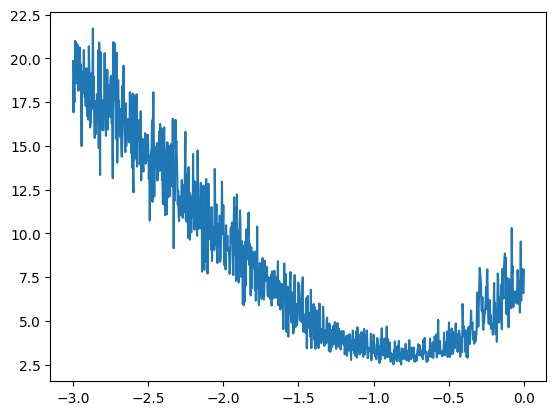

In [ ]:
plt.plot(lri, lossi) # learning rates on X-axis and losses on Y-axis

Determining the learning rate - 02
-----

steps 6 to 8 of finding learning rate

6.   Choose Learning Decay method:

After finding a good initial learning rate we need to select a strategy for reducing the learning rate over time (e.g., step decay, exponential decay, cosine annealing)

Instead of keeping that initial learning rate constant throughout the entire training process, you introduce a learning rate decay schedule. This means that the learning rate will gradually decrease as training progresses

Ways to implement learning rate decay

6.1  Step decay: Reduce the learning rate by a certain factor at specific intervals (e.g., every few epochs).

6.2  Exponential decay: Reduce the learning rate exponentially over time.

6.3  Cosine annealing: Use a cosine function to gradually decrease and sometimes increase the learning rate in a cyclical manner.

7.   Train the model with the optimal initial learning rate and the chosen learning decay:

Now that you have a good estimate for the learning rate and learning decay, you train your model using this initial learning rate, but you apply a learning rate decay schedule to gradually reduce it over the course of training.

8.   Evaluate the model:

After training, you evaluate your model's performance on a separate dataset that it hasn't seen during training (validation or test set) to get an unbiased measure of how well it generalizes.

9. Finish task: Summarize your findings, including the chosen learning rate and the final performance of the model.

In [ ]:
print(f'dataset X:{X.shape} Y:{Y.shape}') # dataset
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

dataset X:torch.Size([228146, 3]) Y:torch.Size([228146])
total parameters 3481


In [ ]:
# setting grad as required to all parameters
for p in parameters:
  p.requires_grad = True

In [ ]:
# find learning rate
lre = torch.linspace(-3, 0, 1000) #creates 1000 numbers between -3 and 0
lrs = 10**lre # logarithmic spaced means the numbers grow logarithmically (https://docs.google.com/document/d/1zKx5FqSWFu_KJ_y6F0nYtMbiGXXnQFGwR27IyiiwW5Q/edit?tab=t.0)


1. train the model with the initial learning rate we got from step 5(eg.0.1) for couple of iterartions

2. Then apply the learning decay by changing the learning rate (for eg use lr = 0.01)

In [ ]:

lri = [] # for tracking learing rates
lossi = [] # for tracking loss

for i in range(10000):
  # mini-batch construct - creating 32 random no between 0 and no of inputs(X.shape[0])
  ix = torch.randint(0, X.shape[0], (32,))

  # forward pass
  emb = C[X[ix]] # randomly selected batch. shape (32, 3, 10)
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Y[ix])
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  lr = 0.1 # this is the learning rate we got form previous sections(ie. step 5 of finding learning rate)
  #lr = 0.01 # apply this learning decay after couple of training with initial learning rate
  for p in parameters:
    p.data += -lr * p.grad

print("loss",loss.item())

loss 2.3257598876953125


Training and evaulating using diff dataset
-----


Here we split the dataset to 3 diff section
1. Training split - roughly 80% of the dataset that is used for training the model

2. Dev/Validation split - roughly 10% of the dataset that is used for devlopment of all hyper parameters of the model

3. Test split - roughly 10% of the dataset used to evaulate the performance model at the end

In [ ]:
# build the dataset for training,dev and test
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []
  for w in words:

    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words) # shuffling the words
n1 = int(0.8*len(words))# 80%
n2 = int(0.9*len(words))# 90%

Xtr, Ytr = build_dataset(words[:n1]) # training dataset, i.e 80% of words
Xdev, Ydev = build_dataset(words[n1:n2]) # dev dataset. i.e 10% of words
Xte, Yte = build_dataset(words[n2:])# test dataset. i.e 10% of words

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [ ]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

# setting grad as required to all parameters
for p in parameters:
  p.requires_grad = True

# find learning rate
lre = torch.linspace(-3, 0, 1000) #creates 1000 numbers between -3 and 0
lrs = 10**lre # logarithmic spaced means the numbers grow logarithmically (https://docs.google.com/document/d/1zKx5FqSWFu_KJ_y6F0nYtMbiGXXnQFGwR27IyiiwW5Q/edit?tab=t.0)


dataset X:torch.Size([228146, 3]) Y:torch.Size([228146])
total parameters 3481


In [ ]:
# training with training set(Xtr&Ytr) data only

lri = [] # for tracking learing rates
lossi = [] # for tracking loss

for i in range(40000):
  # mini-batch construct - creating 32 random no between 0 and no of inputs(X.shape[0])
  ix = torch.randint(0, Xtr.shape[0], (32,))

  # forward pass
  emb = C[Xtr[ix]] # randomly selected batch. shape (32, 3, 10)
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  lr = 0.1 if i < 30000 else 0.01 # initial learning rate and decay rate
  for p in parameters:
    p.data += -lr * p.grad

#print("loss",loss.item())

loss 2.2679810523986816


In [ ]:
# evaulate loss with training dataset
emb = C[Xtr] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3434, grad_fn=<NllLossBackward0>)

In [ ]:
# evaulate loss with dev set(Xdev&Ydev) only
emb = C[Xdev] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.3235, grad_fn=<NllLossBackward0>)

Updating hidden layer - increasing no of neurons
-----

since in previous step the loss against training and dev set was somewhat equal , it means the model is underfitting( which could typically mean the network is small)

In [ ]:
nuerons = 300
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, nuerons), generator=g)
b1 = torch.randn(nuerons, generator=g)
W2 = torch.randn((nuerons, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

# setting grad as required to all parameters
for p in parameters:
  p.requires_grad = True

# find learning rate
lre = torch.linspace(-3, 0, 1000) #creates 1000 numbers between -3 and 0
lrs = 10**lre # logarithmic spaced means the numbers grow logarithmically (https://docs.google.com/document/d/1zKx5FqSWFu_KJ_y6F0nYtMbiGXXnQFGwR27IyiiwW5Q/edit?tab=t.0)


total parameters 10281


In [ ]:
# training with training set(Xtr&Ytr) data only

#lri = [] # for tracking learing rates
lossi = [] # for tracking loss
stepi = [] # for tracking steps

for i in range(40000):
  # mini-batch construct - creating 32 random no between 0 and no of inputs(X.shape[0])
  ix = torch.randint(0, Xtr.shape[0], (32,))

  # forward pass
  emb = C[Xtr[ix]] # randomly selected batch. shape (32, 3, 10)
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  lr = 0.1 if i < 30000 else 0.01 # initial learning rate and decay rate
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  lossi.append(loss.item())
  stepi.append(i)

#print("loss",loss.item())

loss 1.855934500694275


In [ ]:
# evaulate loss with training dataset
emb = C[Xtr] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3133, grad_fn=<NllLossBackward0>)

In [ ]:
# evaulate loss with dev set(Xdev&Ydev) only
emb = C[Xdev] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.3101, grad_fn=<NllLossBackward0>)

Updating input embedding diamension - increasing its dimension form 2 to 10
-----

Even after we added additional nuerons in previous step the loss against training and dev set are still somewhat equal , it means the model is underfitting and the bottleneck could be the input embedding

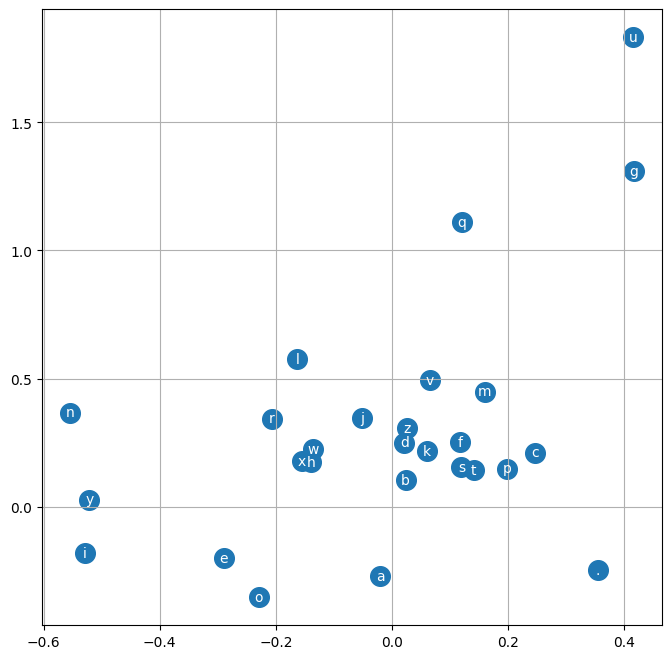

In [ ]:
#Optional:  visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [ ]:
# updation
nuerons = 200
embedding_dim = 10
total_embedding = embedding_dim * 3 # 30

In [ ]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, embedding_dim), generator=g)
W1 = torch.randn((total_embedding, nuerons), generator=g) #30 bcoz, we provide 3 inputs char of 10 embedding values each
b1 = torch.randn(nuerons, generator=g)
W2 = torch.randn((nuerons, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print("total parameters", sum(p.nelement() for p in parameters))

# setting grad as required to all parameters
for p in parameters:
  p.requires_grad = True

# find learning rate
lre = torch.linspace(-3, 0, 1000) #creates 1000 numbers between -3 and 0
lrs = 10**lre # logarithmic spaced means the numbers grow logarithmically (https://docs.google.com/document/d/1zKx5FqSWFu_KJ_y6F0nYtMbiGXXnQFGwR27IyiiwW5Q/edit?tab=t.0)


total parameters 11897


In [ ]:
lossi = [] # for tracking loss
stepi = [] # for tracking steps

In [ ]:
# training with training set(Xtr&Ytr) data only

for i in range(200000):
  # mini-batch construct - creating 32 random no between 0 and no of inputs(X.shape[0])
  ix = torch.randint(0, Xtr.shape[0], (32,))

  # forward pass
  emb = C[Xtr[ix]] # randomly selected batch. shape (32, 3, 10)
  h = torch.tanh(emb.view(-1, total_embedding) @ W1 + b1) # (32, 100)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # setting grads to zero
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # initial learning rate and decay rate
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  lossi.append(loss.log10().item()) # using log10 here to
  stepi.append(i)

#print("loss",loss.item())

loss 1.6591640710830688


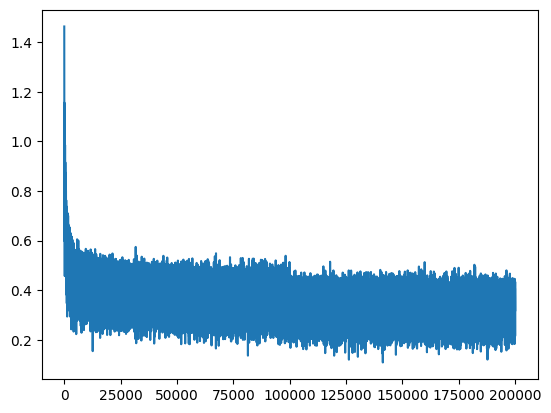

In [ ]:
plt.plot(stepi, lossi)

In [ ]:
# evaulate loss with training dataset
emb = C[Xtr] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, total_embedding) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Ytr)
loss


tensor(2.1310, grad_fn=<NllLossBackward0>)

In [ ]:
# evaulate loss with dev set(Xdev&Ydev) only
emb = C[Xdev] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, total_embedding) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1654, grad_fn=<NllLossBackward0>)

Sampling from model
------

In [ ]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20): # generating 20 samples

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))

eria.
kayah.
seel.
ndury.
lorethrusendraeg.
adelyn.
elin.
shi.
jen.
eden.
estanar.
kayzios.
kalin.
shubergiagriel.
kendreelynn.
nophir.
uzzeyad.
ryyline.
els.
kayshia.


High level Computation Graph of the Neuralnet
-------      



      X (context indices)
           ↓
        C[X] (lookup)
           ↓
     emb.view(-1, 6)
           ↓
       emb @ W1 + b1
           ↓
         tanh
           ↓
         h @ W2 + b2
           ↓
         logits
           ↓
     cross_entropy(logits, Y)
           ↓
          loss